In [2]:

import torch
from google.colab import drive

drive.mount('/content/drive')

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU bulunamadı")


Mounted at /content/drive
GPU: GPU bulunamadı


In [3]:
import os

print("Drive bağlı mı?", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("Drive hazır!")
else:
    print("Drive henüz bağlı değil.")

Drive bağlı mı? True
Drive hazır!


In [1]:

import torch

print("CUDA kullanılabilir mi?", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU henüz aktif değil.")


CUDA kullanılabilir mi? True
GPU: Tesla T4


In [2]:

import os
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Drive hazır!")


Mounted at /content/drive
Drive hazır!


In [3]:

import os

ana_klasor = "/content/drive/MyDrive"

for kok, klasorler, dosyalar in os.walk(ana_klasor):
    if "veri_bolunmesi_v3" in klasorler:
        print("V3 KLASÖRÜ BULUNDU:")
        print(os.path.join(kok, "veri_bolunmesi_v3"))
        break
else:
    print("V3 klasörü Drive'da bulunamadı.")


V3 KLASÖRÜ BULUNDU:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi_v3


In [4]:

import os

v3_klasoru = None

for kok, klasorler, dosyalar in os.walk("/content/drive/MyDrive"):
    if "veri_bolunmesi_v3" in klasorler:
        v3_klasoru = os.path.join(kok, "veri_bolunmesi_v3")
        break

if v3_klasoru:
    print("V3 klasör yolu:", v3_klasoru)
    print("\nKlasördeki dosyalar:")
    for ad in os.listdir(v3_klasoru):
        print("-", ad)
else:
    print("V3 klasörü bulunamadı.")


V3 klasör yolu: /content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi_v3

Klasördeki dosyalar:
- train.csv
- val.csv
- test.csv
- final_veri_hashleri.csv
- ssim_kaldirilan_kayitlar.csv
- final_veri_ozeti.csv
- final_sinif_dagilimi.csv


In [5]:

import os
import pandas as pd

train_df = pd.read_csv(os.path.join(v3_klasoru, "train.csv"))
val_df = pd.read_csv(os.path.join(v3_klasoru, "val.csv"))
test_df = pd.read_csv(os.path.join(v3_klasoru, "test.csv"))

print("Eğitim görüntüsü:", len(train_df))
print("Doğrulama görüntüsü:", len(val_df))
print("Test görüntüsü:", len(test_df))

print("\nCSV sütunları:")
print(train_df.columns.tolist())

print("\nEğitim verisinden ilk 5 satır:")
display(train_df.head())


Eğitim görüntüsü: 3870
Doğrulama görüntüsü: 994
Test görüntüsü: 1579

CSV sütunları:
['dosya', 'sinif']

Eğitim verisinden ilk 5 satır:


,dosya,sinif
0,Training/glioma/Tr-gl_1.jpg,glioma
1,Training/glioma/Tr-gl_100.jpg,glioma
2,Training/glioma/Tr-gl_1000.jpg,glioma
3,Training/glioma/Tr-gl_1001.jpg,glioma
4,Training/glioma/Tr-gl_1002.jpg,glioma


In [6]:

import os

aranan_dosya = "Tr-gl_1.jpg"
bulunan_yollar = []

for kok, klasorler, dosyalar in os.walk("/content/drive/MyDrive"):
    if aranan_dosya in dosyalar:
        bulunan_yollar.append(os.path.join(kok, aranan_dosya))
        if len(bulunan_yollar) >= 5:
            break

if bulunan_yollar:
    print("MR görüntüsü bulundu:")
    for yol in bulunan_yollar:
        print(yol)
else:
    print("MR görüntüsü bulunamadı!")


MR görüntüsü bulunamadı!


In [8]:

import os

for kok, klasorler, dosyalar in os.walk("/content/drive/MyDrive"):
    for klasor in klasorler:
        if klasor.lower() in ["training", "testing"]:
            print(os.path.join(kok, klasor))


In [9]:

import os

print("Colab içindeki klasörler:")
print(os.listdir("/content"))

print("\nDrive'daki v3 klasörü:")
print(v3_klasoru)


Colab içindeki klasörler:
['.config', 'drive', 'sample_data']

Drive'daki v3 klasörü:
/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi_v3


In [10]:

import kagglehub
import os

veri_yolu = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

print("İndirilen veri yolu:", veri_yolu)
print("İçerik:", os.listdir(veri_yolu))


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
İndirilen veri yolu: /kaggle/input/brain-tumor-mri-dataset
İçerik: ['Training', 'Testing']


In [11]:

!pip -q install timm pandas scikit-learn matplotlib


In [12]:

import torch
import pandas as pd
from pathlib import Path
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "GPU bulunamadı")

proje_yolu = Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")
csv_yolu = proje_yolu / "veri_bolunmesi_v3"

train_df = pd.read_csv(csv_yolu / "train.csv")
val_df = pd.read_csv(csv_yolu / "val.csv")
test_df = pd.read_csv(csv_yolu / "test.csv")

print("Eğitim:", len(train_df))
print("Doğrulama:", len(val_df))
print("Test:", len(test_df))


GPU: Tesla T4
Eğitim: 3870
Doğrulama: 994
Test: 1579


In [13]:

from pathlib import Path

proje_yolu = Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")

for yol in proje_yolu.rglob("*"):
    if yol.is_file() and yol.suffix.lower() in [".zip", ".tar", ".gz"]:
        print("Arşiv:", yol)


Arşiv: /content/drive/MyDrive/Beyin_Tumoru_Projesi/Brain_Tumor_MRI_Dataset.zip


In [14]:

from PIL import Image
from torch.utils.data import Dataset

CLASS_TO_IDX = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        satir = self.dataframe.iloc[idx]

        goruntu_yolu = self.root_dir / satir["dosya"]
        sinif = satir["sinif"]
        label = CLASS_TO_IDX[sinif]

        with Image.open(goruntu_yolu) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


In [15]:

from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = val_transform


In [16]:

from pathlib import Path
import zipfile

zip_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/Brain_Tumor_MRI_Dataset.zip"
)

hedef_klasor = Path("/content/Swin_V3_Dataset")
hedef_klasor.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
    zip_ref.extractall(hedef_klasor)

print("ZIP açıldı!")
print("İçindeki klasörler:")
for dosya in hedef_klasor.iterdir():
    print("-", dosya.name)


ZIP açıldı!
İçindeki klasörler:
- Training
- Testing


In [17]:

from pathlib import Path

# CSV'deki Training/glioma/... yolunu bul
ornek_yol = Path(train_df.iloc[0]["dosya"])

adaylar = [
    hedef_klasor,
    *[p for p in hedef_klasor.iterdir() if p.is_dir()]
]

dataset_root = None

for aday in adaylar:
    if (aday / ornek_yol).is_file():
        dataset_root = aday
        break

if dataset_root is None:
    print("Görüntü yolu eşleşmedi!")
    print("CSV örneği:", ornek_yol)
else:
    print("Veri klasörü:", dataset_root)
    print("Örnek görüntü bulundu:", dataset_root / ornek_yol)

    for ad, df in [
        ("Eğitim", train_df),
        ("Doğrulama", val_df),
        ("Test", test_df)
    ]:
        eksikler = [
            yol for yol in df["dosya"]
            if not (dataset_root / yol).is_file()
        ]
        print(f"{ad}: {len(df)} kayıt, {len(eksikler)} eksik görüntü")


Veri klasörü: /content/Swin_V3_Dataset
Örnek görüntü bulundu: /content/Swin_V3_Dataset/Training/glioma/Tr-gl_1.jpg
Eğitim: 3870 kayıt, 0 eksik görüntü
Doğrulama: 994 kayıt, 0 eksik görüntü
Test: 1579 kayıt, 0 eksik görüntü


In [18]:

from torch.utils.data import DataLoader

train_dataset = BrainTumorDataset(
    dataframe=train_df,
    root_dir=dataset_root,
    transform=train_transform
)

val_dataset = BrainTumorDataset(
    dataframe=val_df,
    root_dir=dataset_root,
    transform=val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Eğitim batch sayısı:", len(train_loader))
print("Doğrulama batch sayısı:", len(val_loader))

images, labels = next(iter(train_loader))
print("Görüntü boyutu:", images.shape)
print("Etiket boyutu:", labels.shape)


Eğitim batch sayısı: 242
Doğrulama batch sayısı: 63
Görüntü boyutu: torch.Size([16, 3, 224, 224])
Etiket boyutu: torch.Size([16])


In [19]:

import timm
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

print("Cihaz:", device)
print("Model:", model.__class__.__name__)
print("Çıkış sınıf sayısı:", model.get_classifier().out_features)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Cihaz: cuda
Model: SwinTransformer
Çıkış sınıf sayısı: 4


In [20]:

import torch.nn as nn
from pathlib import Path

EPOCHS = 10
LEARNING_RATE = 2e-5

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

kayit_klasoru = (
    proje_yolu / "modeller"
)
kayit_klasoru.mkdir(parents=True, exist_ok=True)

sonuc_klasoru = (
    proje_yolu / "results" / "swin_v3"
)
sonuc_klasoru.mkdir(parents=True, exist_ok=True)

checkpoint_yolu = (
    kayit_klasoru / "swin_tiny_v3_best.pth"
)

print("Checkpoint:", checkpoint_yolu)
print("Grafikler:", sonuc_klasoru)


Checkpoint: /content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/swin_tiny_v3_best.pth
Grafikler: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3


In [21]:

import copy
import pandas as pd
from tqdm.auto import tqdm

scaler = torch.amp.GradScaler(
    "cuda", enabled=(device.type == "cuda")
)

history = []
best_val_acc = -1.0

for epoch in range(EPOCHS):
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} Eğitim"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} Doğrulama"
        ):
            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += labels.size(0)

    scheduler.step()

    epoch_result = {
        "epoch": epoch + 1,
        "train_loss": train_loss / train_total,
        "train_acc": train_correct / train_total,
        "val_loss": val_loss / val_total,
        "val_acc": val_correct / val_total
    }

    history.append(epoch_result)

    pd.DataFrame(history).to_csv(
        sonuc_klasoru / "training_history.csv",
        index=False
    )

    if epoch_result["val_acc"] > best_val_acc:
        best_val_acc = epoch_result["val_acc"]

        torch.save(
            model.state_dict(),
            checkpoint_yolu
        )

        print("Yeni en iyi model Drive'a kaydedildi!")

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Acc: {epoch_result['train_acc']:.4f} | "
        f"Val Acc: {epoch_result['val_acc']:.4f} | "
        f"Val Loss: {epoch_result['val_loss']:.4f}"
    )

print("Eğitim tamamlandı!")
print("En iyi validation accuracy:", best_val_acc)


Epoch 1/10 Eğitim:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 1/10 Doğrulama:   0%|          | 0/63 [00:00<?, ?it/s]

Yeni en iyi model Drive'a kaydedildi!
Epoch 1/10 | Train Acc: 0.8633 | Val Acc: 0.9477 | Val Loss: 0.1394


Epoch 2/10 Eğitim:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 2/10 Doğrulama:   0%|          | 0/63 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e59e2cc0900>Exception ignored in: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e59e2cc0900>
    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

... (31 outputs left out)

Epoch 10/10 Eğitim:   0%|          | 0/242 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e59e2cc0900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e59e2cc0900>    
assert self._parent_pid == os.getpid(), 'can only test a child process'Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    AssertionError: self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored 

Epoch 10/10 Doğrulama:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 10/10 | Train Acc: 0.9979 | Val Acc: 0.9829 | Val Loss: 0.0684
Eğitim tamamlandı!
En iyi validation accuracy: 0.9839034205231388


In [1]:

import torch
from pathlib import Path

checkpoint_yolu = (
    Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")
    / "modeller"
    / "swin_tiny_v3_best.pth"
)

print("Model dosyası mevcut:", checkpoint_yolu.exists())

model.load_state_dict(
    torch.load(
        checkpoint_yolu,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("En iyi Swin-Tiny V3 modeli başarıyla yüklendi!")


Model dosyası mevcut: False


NameError: name 'model' is not defined

In [2]:

from pathlib import Path
from google.colab import drive

# Drive bağlı değilse bağla
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

print("SWIN MODEL DOSYALARI")
print("-" * 40)

bulunanlar = list(
    Path("/content/drive/MyDrive").rglob("*swin*.pth")
)

if bulunanlar:
    for dosya in bulunanlar:
        print("Bulundu:", dosya)
        print("Boyut (MB):", round(
            dosya.stat().st_size / (1024 ** 2), 2
        ))
else:
    print("Drive içinde Swin model dosyası bulunamadı.")

print("\nSONUÇ KLASÖRLERİ")
print("-" * 40)

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

for klasor in [
    proje_yolu / "modeller",
    proje_yolu / "results" / "swin_v3"
]:
    print("\nKlasör:", klasor)
    if klasor.exists():
        for dosya in klasor.iterdir():
            print("-", dosya.name)
    else:
        print("Klasör bulunamadı.")


Mounted at /content/drive
SWIN MODEL DOSYALARI
----------------------------------------
Bulundu: /content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/swin_tiny_best.pth
Boyut (MB): 105.06
Bulundu: /content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/swin_tiny_v3_best.pth
Boyut (MB): 105.06

SONUÇ KLASÖRLERİ
----------------------------------------

Klasör: /content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller
- swin_tiny_best.pth
- cnn_best.pth
- vit_best.pth
- sam_vit_b_01ec64.pth
- swin_tiny_v3_best.pth
- cnn_v2_best.pth
- cnn_v2_last.pth

Klasör: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3
- training_history.csv


In [3]:

import torch
import timm
from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Eğitimde kullandığımız mimariyi yeniden oluştur
model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=False,
    num_classes=4
)

# V3 eğitiminde kaydettiğimiz ağırlıkları yükle
checkpoint_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/"
    "modeller/swin_tiny_v3_best.pth"
)

model.load_state_dict(
    torch.load(
        checkpoint_yolu,
        map_location="cpu",
        weights_only=True
    )
)

model = model.to(device)
model.eval()

print("Swin-Tiny V3 başarıyla yüklendi!")
print("Cihaz:", device)
print("Checkpoint:", checkpoint_yolu.name)


Swin-Tiny V3 başarıyla yüklendi!
Cihaz: cuda
Checkpoint: swin_tiny_v3_best.pth


In [4]:

import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# V3 test CSV dosyası
proje_yolu = Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")
test_df = pd.read_csv(
    proje_yolu / "veri_bolunmesi_v3" / "test.csv"
)

# ZIP'ten çıkardığımız görüntülerin klasörü
dataset_root = Path("/content/Swin_V3_Dataset")

CLASS_TO_IDX = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        satir = self.dataframe.iloc[idx]
        goruntu_yolu = self.root_dir / satir["dosya"]

        with Image.open(goruntu_yolu) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = CLASS_TO_IDX[satir["sinif"]]
        return image, label

# Test görüntülerinin mevcut olduğunu kontrol et
eksik = [
    yol for yol in test_df["dosya"]
    if not (dataset_root / yol).is_file()
]

print("Test görüntüsü:", len(test_df))
print("Eksik görüntü:", len(eksik))

if eksik:
    raise FileNotFoundError(
        "Bazı test görüntüleri bulunamadı. "
        "ZIP'i yeniden açmak gerekebilir."
    )

test_dataset = BrainTumorDataset(
    test_df,
    dataset_root,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test batch sayısı:", len(test_loader))
print("Test verileri hazır!")


Test görüntüsü: 1579
Eksik görüntü: 1579


FileNotFoundError: Bazı test görüntüleri bulunamadı. ZIP'i yeniden açmak gerekebilir.

In [5]:

from pathlib import Path
import zipfile

zip_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/"
    "Brain_Tumor_MRI_Dataset.zip"
)

dataset_root = Path("/content/Swin_V3_Dataset")

print("ZIP mevcut:", zip_yolu.exists())

if not zip_yolu.exists():
    raise FileNotFoundError("Drive'daki ZIP bulunamadı.")

# Görüntüler eksikse ZIP'i yeniden aç
ornek_goruntu = dataset_root / test_df.iloc[0]["dosya"]

if not ornek_goruntu.is_file():
    print("Görüntüler Colab'a yeniden çıkarılıyor...")

    dataset_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
        zip_ref.extractall(dataset_root)

    print("ZIP açıldı!")
else:
    print("Görüntüler zaten mevcut.")

# V3 test listesindeki bütün dosyaları doğrula
eksik = [
    yol for yol in test_df["dosya"]
    if not (dataset_root / yol).is_file()
]

print("Test görüntüsü:", len(test_df))
print("Eksik görüntü:", len(eksik))

if len(eksik) == 0:
    print("✅ Test verileri hazır!")
else:
    print("İlk eksik dosya:", eksik[0])


ZIP mevcut: True
Görüntüler Colab'a yeniden çıkarılıyor...
ZIP açıldı!
Test görüntüsü: 1579
Eksik görüntü: 0
✅ Test verileri hazır!


In [6]:

import torch
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# En iyi eğitilmiş modelin yüklü olduğundan emin ol
model.eval()

# Tahminleri ve gerçek etiketleri topla
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(
        test_loader,
        desc="Swin-Tiny V3 Test"
    ):
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

# Genel başarı
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

siniflar = ["glioma", "meningioma", "notumor", "pituitary"]

print("\nSWIN-TINY V3 TEST SONUÇLARI")
print("-" * 40)
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")

print("\nSINIF BAZLI RAPOR")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=siniflar,
        zero_division=0
    )
)

# Sonuçları Drive'a kaydet
sonuc_klasoru = (
    Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")
    / "results"
    / "swin_v3"
)
sonuc_klasoru.mkdir(parents=True, exist_ok=True)

rapor = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=siniflar,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(rapor).transpose().to_csv(
    sonuc_klasoru / "classification_report.csv"
)

pd.DataFrame({
    "gercek": y_true,
    "tahmin": y_pred
}).to_csv(
    sonuc_klasoru / "test_predictions.csv",
    index=False
)

print("\nTest sonuçları Google Drive'a kaydedildi!")


NameError: name 'test_loader' is not defined

In [7]:

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CLASS_TO_IDX = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

dataset_root = Path("/content/Swin_V3_Dataset")

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        satir = self.dataframe.iloc[idx]
        goruntu_yolu = self.root_dir / satir["dosya"]

        with Image.open(goruntu_yolu) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = CLASS_TO_IDX[satir["sinif"]]
        return image, label

test_dataset = BrainTumorDataset(
    dataframe=test_df,
    root_dir=dataset_root,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test görüntüsü:", len(test_dataset))
print("Test batch sayısı:", len(test_loader))

images, labels = next(iter(test_loader))
print("İlk batch boyutu:", images.shape)
print("Test DataLoader hazır!")


Test görüntüsü: 1579
Test batch sayısı: 99
İlk batch boyutu: torch.Size([16, 3, 224, 224])
Test DataLoader hazır!


In [8]:

import torch
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(
        test_loader,
        desc="Swin-Tiny V3 Test"
    ):
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

siniflar = ["glioma", "meningioma", "notumor", "pituitary"]

print("\nSWIN-TINY V3 TEST SONUÇLARI")
print("-" * 40)
print(f"Accuracy : %{accuracy * 100:.2f}")
print(f"Precision: %{precision * 100:.2f}")
print(f"Recall   : %{recall * 100:.2f}")
print(f"F1-Score : %{f1 * 100:.2f}")

print("\nSINIF BAZLI RAPOR")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=siniflar,
    zero_division=0
))

sonuc_klasoru = (
    Path("/content/drive/MyDrive/Beyin_Tumoru_Projesi")
    / "results" / "swin_v3"
)
sonuc_klasoru.mkdir(parents=True, exist_ok=True)

pd.DataFrame({
    "dosya": test_df["dosya"].tolist(),
    "gercek": y_true,
    "tahmin": y_pred
}).to_csv(
    sonuc_klasoru / "test_predictions.csv",
    index=False
)

print("\nTahminler Google Drive'a kaydedildi.")


Swin-Tiny V3 Test:   0%|          | 0/99 [00:00<?, ?it/s]


SWIN-TINY V3 TEST SONUÇLARI
----------------------------------------
Accuracy : %93.86
Precision: %94.48
Recall   : %93.86
F1-Score : %93.82

SINIF BAZLI RAPOR
              precision    recall  f1-score   support

      glioma       0.99      0.83      0.90       383
  meningioma       0.96      0.93      0.94       396
     notumor       0.85      1.00      0.92       400
   pituitary       0.98      0.99      0.99       400

    accuracy                           0.94      1579
   macro avg       0.95      0.94      0.94      1579
weighted avg       0.94      0.94      0.94      1579


Tahminler Google Drive'a kaydedildi.


SWIN-TINY V3 TEST SONUÇLARI
----------------------------------------
Test Accuracy: %93.86

               precision    recall  f1-score   support

      glioma       0.99      0.83      0.90       383
  meningioma       0.96      0.93      0.94       396
     notumor       0.85      1.00      0.92       400
   pituitary       0.98      0.99      0.99       400

    accuracy                           0.94      1579
   macro avg       0.95      0.94      0.94      1579
weighted avg       0.94      0.94      0.94      1579



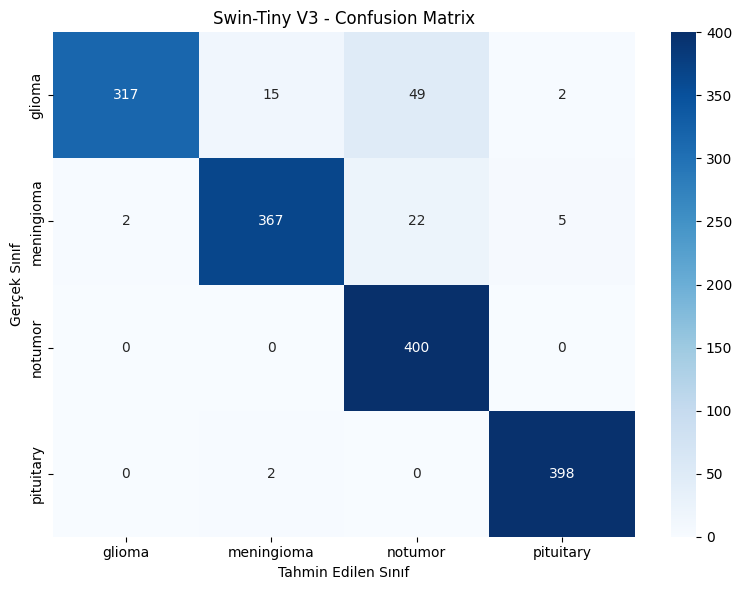


Rapor ve grafik Google Drive'a kaydedildi!


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

sonuc_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3"
)

df = pd.read_csv(sonuc_klasoru / "test_predictions.csv")

y_true = df["gercek"]
y_pred = df["tahmin"]

siniflar = ["glioma", "meningioma", "notumor", "pituitary"]

print("SWIN-TINY V3 TEST SONUÇLARI")
print("-" * 40)
print(f"Test Accuracy: %{accuracy_score(y_true, y_pred)*100:.2f}")

rapor = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=siniflar,
    zero_division=0
)

print("\n", rapor)

with open(sonuc_klasoru / "classification_report.txt", "w") as f:
    f.write(rapor)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=siniflar,
    yticklabels=siniflar
)

plt.title("Swin-Tiny V3 - Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()

plt.savefig(
    sonuc_klasoru / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nRapor ve grafik Google Drive'a kaydedildi!")


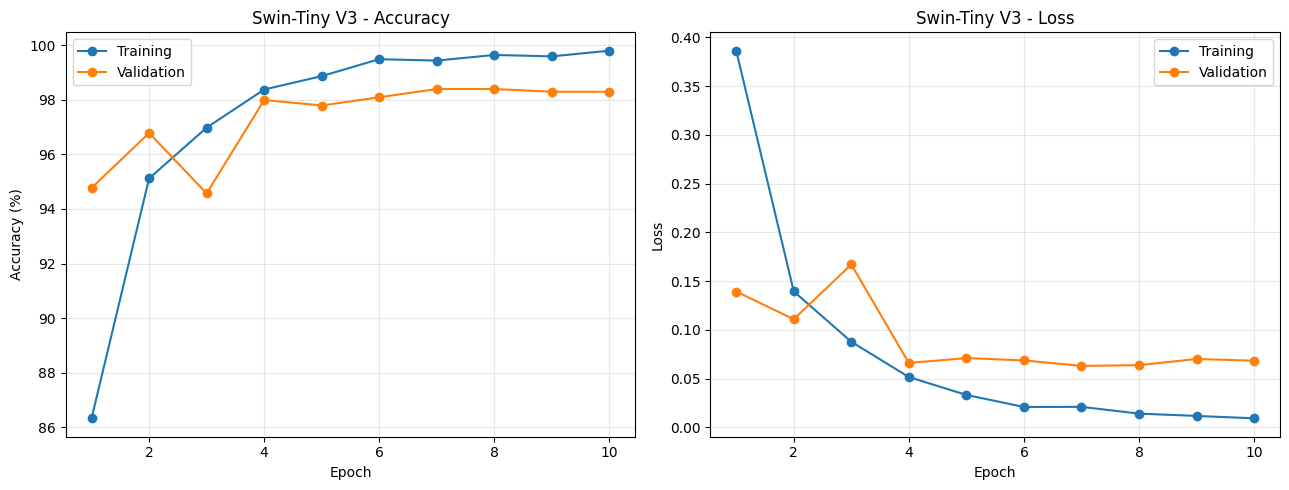

Eğitim grafikleri Drive'a kaydedildi!


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sonuc_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3"
)

history = pd.read_csv(
    sonuc_klasoru / "training_history.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy grafiği
axes[0].plot(
    history["epoch"],
    history["train_acc"] * 100,
    marker="o",
    label="Training"
)
axes[0].plot(
    history["epoch"],
    history["val_acc"] * 100,
    marker="o",
    label="Validation"
)
axes[0].set_title("Swin-Tiny V3 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss grafiği
axes[1].plot(
    history["epoch"],
    history["train_loss"],
    marker="o",
    label="Training"
)
axes[1].plot(
    history["epoch"],
    history["val_loss"],
    marker="o",
    label="Validation"
)
axes[1].set_title("Swin-Tiny V3 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    sonuc_klasoru / "training_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Eğitim grafikleri Drive'a kaydedildi!")


In [11]:

import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sonuc_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3"
)

tahminler = pd.read_csv(
    sonuc_klasoru / "test_predictions.csv"
)

gercek = tahminler["gercek"]
tahmin = tahminler["tahmin"]

ozet = pd.DataFrame([{
    "Model": "Swin-Tiny V3",
    "Veri Bölünmesi": "veri_bolunmesi_v3",
    "Test Görüntüsü": len(tahminler),
    "Accuracy (%)": round(
        accuracy_score(gercek, tahmin) * 100, 2
    ),
    "Precision (%)": round(
        precision_score(
            gercek, tahmin,
            average="weighted",
            zero_division=0
        ) * 100, 2
    ),
    "Recall (%)": round(
        recall_score(
            gercek, tahmin,
            average="weighted",
            zero_division=0
        ) * 100, 2
    ),
    "F1-score (%)": round(
        f1_score(
            gercek, tahmin,
            average="weighted",
            zero_division=0
        ) * 100, 2
    )
}])

display(ozet)

ozet.to_csv(
    sonuc_klasoru / "swin_v3_summary.csv",
    index=False
)

print("Özet tablo Drive'a kaydedildi!")


,Model,Veri Bölünmesi,Test Görüntüsü,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Swin-Tiny V3,veri_bolunmesi_v3,1579,93.86,94.48,93.86,93.82


Özet tablo Drive'a kaydedildi!


In [12]:

from pathlib import Path
import zipfile

kaynak = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/results/swin_v3"
)

zip_yolu = Path("/content/swin_v3_github_results.zip")

# GitHub'a ekleyeceğimiz sonuç dosyaları
dosyalar = [
    "training_history.csv",
    "test_predictions.csv",
    "classification_report.txt",
    "confusion_matrix.png",
    "training_curves.png",
    "swin_v3_summary.csv"
]

with zipfile.ZipFile(zip_yolu, "w", zipfile.ZIP_DEFLATED) as z:
    for ad in dosyalar:
        dosya = kaynak / ad
        if dosya.exists():
            z.write(dosya, arcname=f"results/swin_v3/{ad}")
            print("Eklendi:", ad)
        else:
            print("Bulunamadı:", ad)

print("\nZIP hazır:", zip_yolu)

from google.colab import files
files.download(str(zip_yolu))


Eklendi: training_history.csv
Eklendi: test_predictions.csv
Eklendi: classification_report.txt
Eklendi: confusion_matrix.png
Eklendi: training_curves.png
Eklendi: swin_v3_summary.csv

ZIP hazır: /content/swin_v3_github_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>